# PA3 — Poucos rótulos: fauna em câmeras trap

## Parte 0 — O piso

Classificador supervisionado usando **apenas** `rotulos_5.csv` (5 rótulos/classe = 105 imagens), em duas versões:

- **(a)** CNN pequena treinada do zero;
- **(b)** ResNet-18 (pesos ImageNet) com fine-tuning — o backbone do resto do PA.

**Protocolo:** a época é escolhida pelo F1 macro no `val`. O `test_public` só é medido no final, uma vez por modelo.
Tudo roda em CPU (ResNet-18 = 11,7 M de parâmetros, abaixo do limite de 12 M).

In [1]:
import sys, csv, json, os, subprocess
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "src" / "common.py").exists():
    # Kernel remoto (Colab): baixa o repositório com código e pa3_dados para a VM
    ROOT = Path("/content/PA3-Deep-learning")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "https://github.com/RaphaellaRoma/PA3-Deep-learning.git", str(ROOT)], check=True)
    else:
        subprocess.run(["git", "-C", str(ROOT), "pull"], check=True)
print("raiz do projeto:", ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import DataLoader
import common as C

SEED, BUDGET, BS = 0, 5, 32
EPOCHS_SCRATCH, EPOCHS_RESNET = 40, 20
torch.set_num_threads(max(1, torch.get_num_threads()))
names, c2i = C.load_classes(); NC = len(names)
OUT = ROOT / "results" / "parte0"; OUT.mkdir(parents=True, exist_ok=True)
print("device:", C.DEVICE, "| threads:", torch.get_num_threads(), "| classes:", NC)


raiz do projeto: /content/PA3-Deep-learning
device: cuda | threads: 1 | classes: 21


## Dados

In [2]:
train_items = C.read_split(f"rotulos_{BUDGET}.csv", "train")
train_ds = C.CachedImages(train_items, c2i, train=True)
val_ds   = C.CachedImages(C.read_split("val.csv", "val"), c2i, train=False)
test_ds  = C.CachedImages(C.read_split("test_public.csv", "test_public"), c2i, train=False)
val_dl, test_dl = DataLoader(val_ds, 64), DataLoader(test_ds, 64)
print(f"treino={len(train_ds)}  val={len(val_ds)}  test_public={len(test_ds)}")
print("rótulos por classe no treino:", pd.Series([l for _, l in train_items]).value_counts().unique())

treino=105  val=202  test_public=811
rótulos por classe no treino: [5]


## Versão (a) — CNN pequena do zero

In [3]:
def make_loader(seed):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(train_ds, BS, shuffle=True, drop_last=True, generator=g)

C.set_seed(SEED)
model_a = C.small_cnn(NC)
print("parâmetros:", f"{C.count_params(model_a):,}")
import time; t0 = time.perf_counter()
hist_a, ep_a, state_a = C.fit(model_a, make_loader(SEED), val_dl, EPOCHS_SCRATCH, lr=2e-3, num_classes=NC)
time_a = time.perf_counter() - t0
model_a.load_state_dict(state_a)
print(f"tempo de treino: {time_a/60:.1f} min")
print("melhor época (val F1):", ep_a)

parâmetros: 1,170,869
ep 01 | treino loss 3.300 acc 0.031 | val loss 3.057 acc 0.050 F1 0.005
ep 02 | treino loss 2.792 acc 0.104 | val loss 3.324 acc 0.025 F1 0.010
ep 03 | treino loss 2.854 acc 0.167 | val loss 3.553 acc 0.040 F1 0.016
ep 04 | treino loss 2.808 acc 0.135 | val loss 3.533 acc 0.035 F1 0.012
ep 05 | treino loss 2.737 acc 0.167 | val loss 3.681 acc 0.069 F1 0.041
ep 06 | treino loss 2.540 acc 0.240 | val loss 3.533 acc 0.069 F1 0.028
ep 07 | treino loss 2.526 acc 0.198 | val loss 3.720 acc 0.099 F1 0.041
ep 08 | treino loss 2.428 acc 0.229 | val loss 4.328 acc 0.129 F1 0.063
ep 09 | treino loss 2.482 acc 0.188 | val loss 3.813 acc 0.158 F1 0.114
ep 10 | treino loss 2.416 acc 0.271 | val loss 3.650 acc 0.064 F1 0.026
ep 11 | treino loss 2.370 acc 0.260 | val loss 3.359 acc 0.089 F1 0.047
ep 12 | treino loss 2.396 acc 0.219 | val loss 3.202 acc 0.124 F1 0.077
ep 13 | treino loss 2.335 acc 0.229 | val loss 3.116 acc 0.114 F1 0.075
ep 14 | treino loss 2.314 acc 0.292 | val 

## Versão (b) — ResNet-18 ImageNet + fine-tuning

**Configuração final:** 224 px, AdamW com `lr=3e-4`, 20 épocas, época escolhida pelo F1 macro no `val`. Testamos 224/320 px × lr 3e-4/1e-3 no `val` e não houve ganho confiável (diferenças dentro do ruído de 202 imagens, e 320 px custa >2× o tempo); os resultados do grid ficaram arquivados em `results/parte0/arquivo_grid/`.

In [4]:
C.set_seed(SEED)
model_b = C.resnet18(NC, pretrained=True)
print("parâmetros:", f"{C.count_params(model_b):,}", "(limite 12.000.000)")
t0 = time.perf_counter()
hist_b, ep_b, state_b = C.fit(model_b, make_loader(SEED), val_dl, EPOCHS_RESNET, lr=3e-4, num_classes=NC)
time_b = time.perf_counter() - t0
model_b.load_state_dict(state_b)
print(f"tempo de treino: {time_b/60:.1f} min")
print("melhor época (val F1):", ep_b)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s] 


parâmetros: 11,187,285 (limite 12.000.000)
ep 01 | treino loss 3.123 acc 0.125 | val loss 2.757 acc 0.193 F1 0.149
ep 02 | treino loss 1.916 acc 0.531 | val loss 2.527 acc 0.267 F1 0.241
ep 03 | treino loss 1.306 acc 0.781 | val loss 2.368 acc 0.292 F1 0.299
ep 04 | treino loss 0.989 acc 0.833 | val loss 2.247 acc 0.342 F1 0.337
ep 05 | treino loss 0.671 acc 0.917 | val loss 2.165 acc 0.371 F1 0.374
ep 06 | treino loss 0.461 acc 0.958 | val loss 2.155 acc 0.351 F1 0.367
ep 07 | treino loss 0.372 acc 0.948 | val loss 2.158 acc 0.332 F1 0.353
ep 08 | treino loss 0.322 acc 0.958 | val loss 2.175 acc 0.332 F1 0.351
ep 09 | treino loss 0.184 acc 1.000 | val loss 2.175 acc 0.342 F1 0.352
ep 10 | treino loss 0.178 acc 0.990 | val loss 2.183 acc 0.332 F1 0.335
ep 11 | treino loss 0.197 acc 0.979 | val loss 2.193 acc 0.322 F1 0.325
ep 12 | treino loss 0.143 acc 0.990 | val loss 2.187 acc 0.327 F1 0.331
ep 13 | treino loss 0.141 acc 0.990 | val loss 2.174 acc 0.347 F1 0.349
ep 14 | treino loss 0

## Curva de treino e validação (versão b)

Com 105 imagens, em que época a rede começa a decorar? Procuramos o ponto em que a loss de validação para de cair
(ou sobe) enquanto a acurácia de treino continua subindo.

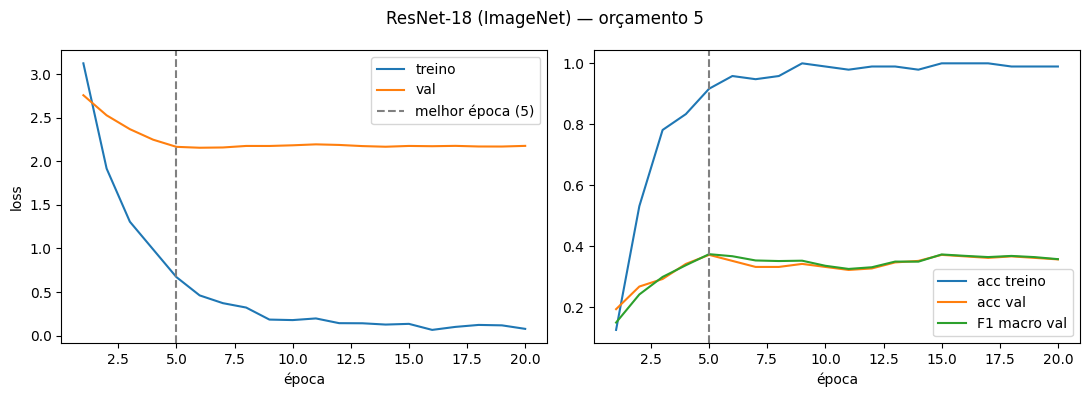

época com menor loss de val: 6 | melhor F1 val: 5


In [5]:
h = pd.DataFrame(hist_b)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h.epoch, h.train_loss, label="treino"); ax[0].plot(h.epoch, h.val_loss, label="val")
ax[0].axvline(ep_b, ls="--", c="gray", label=f"melhor época ({ep_b})"); ax[0].set(xlabel="época", ylabel="loss"); ax[0].legend()
ax[1].plot(h.epoch, h.train_acc, label="acc treino"); ax[1].plot(h.epoch, h.val_acc, label="acc val")
ax[1].plot(h.epoch, h.val_f1, label="F1 macro val"); ax[1].axvline(ep_b, ls="--", c="gray")
ax[1].set(xlabel="época"); ax[1].legend()
fig.suptitle("ResNet-18 (ImageNet) — orçamento 5"); fig.tight_layout()
fig.savefig(OUT / f"resnet18_b{BUDGET}_s{SEED}_curvas.png", dpi=120); plt.show()
print("época com menor loss de val:", int(h.val_loss.idxmin()) + 1, "| melhor F1 val:", int(h.val_f1.idxmax()) + 1)
h.to_csv(OUT / f"resnet18_b{BUDGET}_s{SEED}_history.csv", index=False)
pd.DataFrame(hist_a).to_csv(OUT / f"scratch_b{BUDGET}_s{SEED}_history.csv", index=False)

## Resultados no `test_public` (medido uma única vez)

In [6]:
ta = C.evaluate(model_a, test_dl, "cpu", NC)
tb = C.evaluate(model_b, test_dl, "cpu", NC)
res = pd.DataFrame({
    "modelo": ["(a) CNN do zero", "(b) ResNet-18 ImageNet + FT"],
    "parâmetros": [C.count_params(model_a), C.count_params(model_b)],
    "época (val)": [ep_a, ep_b],
    "F1 macro": [ta["f1_macro"], tb["f1_macro"]],
    "acurácia": [ta["acc"], tb["acc"]],
}).round(4)
res

,modelo,parâmetros,época (val),F1 macro,acurácia
0,(a) CNN do zero,1170869,29,0.1335,0.1492
1,(b) ResNet-18 ImageNet + FT,11187285,5,0.4349,0.4587


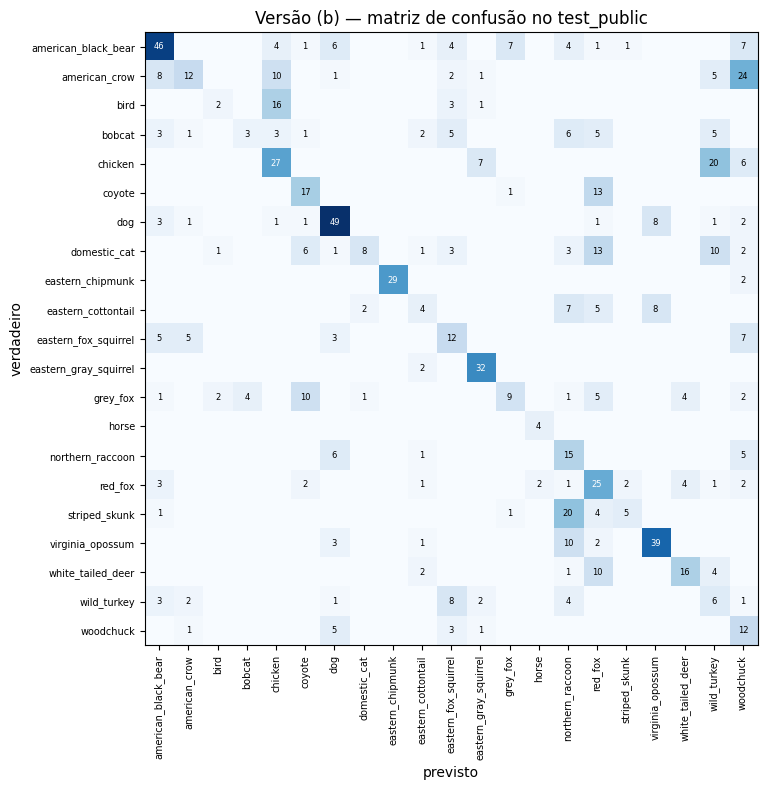

                       precision    recall  f1-score   support

  american_black_bear       0.63      0.56      0.59        82
        american_crow       0.55      0.19      0.28        63
                 bird       0.40      0.09      0.15        22
               bobcat       0.43      0.09      0.15        34
              chicken       0.44      0.45      0.45        60
               coyote       0.45      0.55      0.49        31
                  dog       0.65      0.73      0.69        67
         domestic_cat       0.73      0.17      0.27        48
     eastern_chipmunk       1.00      0.94      0.97        31
   eastern_cottontail       0.27      0.15      0.20        26
 eastern_fox_squirrel       0.30      0.38      0.33        32
eastern_gray_squirrel       0.73      0.94      0.82        34
             grey_fox       0.50      0.23      0.32        39
                horse       0.67      1.00      0.80         4
     northern_raccoon       0.21      0.56      0.30  

In [7]:
cm = confusion_matrix(tb["y"], tb["pred"], labels=list(range(NC)))
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NC), names, rotation=90, fontsize=7); ax.set_yticks(range(NC), names, fontsize=7)
for i in range(NC):
    for j in range(NC):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6, color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set(xlabel="previsto", ylabel="verdadeiro", title="Versão (b) — matriz de confusão no test_public")
fig.tight_layout(); fig.savefig(OUT / f"resnet18_b{BUDGET}_s{SEED}_confusao.png", dpi=120); plt.show()
print(classification_report(tb["y"], tb["pred"], labels=list(range(NC)), target_names=names, zero_division=0))

## Salvando pesos e números (base da Parte 2)

In [8]:
torch.save(state_a, OUT / f"scratch_b{BUDGET}_s{SEED}.pt")
torch.save(state_b, OUT / f"resnet18_b{BUDGET}_s{SEED}.pt")

cb = ROOT / "curva_orcamento.csv"
rows = pd.read_csv(cb) if cb.exists() else pd.DataFrame(columns=["metodo", "orcamento", "seed", "f1_macro", "acuracia"])
novas = pd.DataFrame([
    ["piso_scratch",  BUDGET, SEED, round(ta["f1_macro"], 4), round(ta["acc"], 4)],
    ["piso_resnet18", BUDGET, SEED, round(tb["f1_macro"], 4), round(tb["acc"], 4)]], columns=rows.columns)
rows = rows[~((rows.metodo.isin(novas.metodo)) & (rows.orcamento == BUDGET) & (rows.seed == SEED))]
pd.concat([rows, novas]).to_csv(cb, index=False)
pd.read_csv(cb)

,metodo,orcamento,seed,f1_macro,acuracia
0,piso_scratch,5,0,0.1335,0.1492
1,piso_resnet18,5,0,0.4349,0.4587


### Comparação: CNN v1 (original) vs CNN atual
Baseline guardado em `results/parte0/baseline_cnn_v1/` (tempo informado pelo usuário, não cronometrado em código).

In [9]:
base = json.load(open(OUT / "baseline_cnn_v1" / "baseline.json", encoding="utf8"))
json.dump({"scratch_min": time_a/60, "resnet18_min": time_b/60}, open(OUT / "tempos_min.json", "w"))
pd.DataFrame([
    ["CNN v1 (original)", base["parametros"], base["tempo_treino_min"], base["test_f1_macro"], base["test_acuracia"]],
    ["CNN atual (stem stride 2)", C.count_params(model_a), round(time_a/60, 1), round(ta["f1_macro"], 4), round(ta["acc"], 4)],
], columns=["modelo", "parâmetros", "tempo (min)", "F1 macro test", "acurácia test"])

,modelo,parâmetros,tempo (min),F1 macro test,acurácia test
0,CNN v1 (original),1178613,28.0,0.1411,0.1973
1,CNN atual (stem stride 2),1170869,0.7,0.1335,0.1492


### Conclusão da Parte 0
- Piso (a), CNN do zero: F1 macro ≈ 0,13; piso (b), ResNet-18 + ImageNet: F1 macro ≈ 0,44 (teto de referência: 0,686).
- A ResNet-18 decora cedo: a acurácia de treino passa de 0,95 na época 6, que também é a época de menor loss de validação.
- Os números exatos estão nas tabelas acima e em `curva_orcamento.csv`.

---
# Parte 1 — Trilha A: auto-supervisionado (SimCLR)

Continuamos o pré-treino do backbone nas 6.505 imagens do `train` **sem usar rótulos**.
Treinamos dois backbones: **ImageNet + SimCLR** e **aleatório + SimCLR** (o terceiro, ImageNet puro, já é o da Parte 0).

> **Rodar no Colab com GPU.** Os pré-treinos são a parte pesada. Só os pesos do backbone (`.pt`) voltam para a CPU:
> avaliação linear, fine-tuning, `predict.py` e a contagem de parâmetros rodam em CPU.
> Os pré-treinos salvam checkpoint a cada 2 épocas e retomam sozinhos se a sessão cair.

In [10]:
import simclr as S
OUT1 = ROOT / "results" / "parte1"; OUT1.mkdir(parents=True, exist_ok=True)
EPOCHS_SSL, BS_SSL, SIZE_SSL = 50, 256, 160   # 50 épocas com aumentação em GPU (~3-5 min por pré-treino)
FORCE_RETRAIN = False  # Se False, reaproveita resultados já salvos em results/parte1/ sem treinar de novo
NW = 0
print("device:", C.DEVICE, "| imagens sem rótulo:", len(S.unlabeled_train_paths()))


device: cuda | workers: 2 | imagens sem rótulo: 6505


In [11]:
# ImageNet + SimCLR (se já existir em results/parte1, apenas carrega e mostra o resumo)
_, log_img = S.pretrain("imagenet", EPOCHS_SSL, OUT1, "imagenet_ssl", bs=BS_SSL, img_size=SIZE_SSL, force=FORCE_RETRAIN)


[imagenet_ssl] ep 1/100 loss 4.9408 (40s)
[imagenet_ssl] ep 2/100 loss 4.7084 (40s)
[imagenet_ssl] ep 3/100 loss 4.6313 (39s)
[imagenet_ssl] ep 4/100 loss 4.5986 (39s)
[imagenet_ssl] ep 5/100 loss 4.5705 (41s)
[imagenet_ssl] ep 6/100 loss 4.5703 (40s)
[imagenet_ssl] ep 7/100 loss 4.5480 (39s)
[imagenet_ssl] ep 8/100 loss 4.5299 (41s)
[imagenet_ssl] ep 9/100 loss 4.5298 (41s)
[imagenet_ssl] ep 10/100 loss 4.5296 (40s)
[imagenet_ssl] ep 11/100 loss 4.5098 (40s)
[imagenet_ssl] ep 12/100 loss 4.5074 (40s)
[imagenet_ssl] ep 13/100 loss 4.5049 (40s)
[imagenet_ssl] ep 14/100 loss 4.4936 (41s)
[imagenet_ssl] ep 15/100 loss 4.4842 (40s)
[imagenet_ssl] ep 16/100 loss 4.4856 (39s)
[imagenet_ssl] ep 17/100 loss 4.4767 (40s)
[imagenet_ssl] ep 18/100 loss 4.4628 (40s)
[imagenet_ssl] ep 19/100 loss 4.4712 (39s)
[imagenet_ssl] ep 20/100 loss 4.4731 (39s)
[imagenet_ssl] ep 21/100 loss 4.4643 (39s)
[imagenet_ssl] ep 22/100 loss 4.4577 (37s)
[imagenet_ssl] ep 23/100 loss 4.4562 (38s)
[imagenet_ssl] ep 24

In [12]:
# Aleatório + SimCLR (se já existir em results/parte1, apenas carrega e mostra o resumo)
_, log_rnd = S.pretrain("random", EPOCHS_SSL, OUT1, "random_ssl", bs=BS_SSL, img_size=SIZE_SSL, force=FORCE_RETRAIN)


[random_ssl] ep 1/100 loss 5.6512 (38s)
[random_ssl] ep 2/100 loss 5.3640 (38s)
[random_ssl] ep 3/100 loss 5.2589 (38s)
[random_ssl] ep 4/100 loss 5.2079 (37s)
[random_ssl] ep 5/100 loss 5.1548 (38s)
[random_ssl] ep 6/100 loss 5.1266 (38s)
[random_ssl] ep 7/100 loss 5.0682 (37s)
[random_ssl] ep 8/100 loss 5.0463 (37s)
[random_ssl] ep 9/100 loss 5.0252 (38s)
[random_ssl] ep 10/100 loss 5.0017 (38s)
[random_ssl] ep 11/100 loss 4.9662 (38s)
[random_ssl] ep 12/100 loss 4.9375 (37s)
[random_ssl] ep 13/100 loss 4.9158 (38s)
[random_ssl] ep 14/100 loss 4.8959 (37s)
[random_ssl] ep 15/100 loss 4.8545 (37s)
[random_ssl] ep 16/100 loss 4.8533 (38s)
[random_ssl] ep 17/100 loss 4.8200 (38s)
[random_ssl] ep 18/100 loss 4.8035 (38s)
[random_ssl] ep 19/100 loss 4.7950 (38s)
[random_ssl] ep 20/100 loss 4.7694 (38s)
[random_ssl] ep 21/100 loss 4.7571 (38s)
[random_ssl] ep 22/100 loss 4.7543 (37s)
[random_ssl] ep 23/100 loss 4.7399 (37s)
[random_ssl] ep 24/100 loss 4.7360 (38s)
[random_ssl] ep 25/100 lo

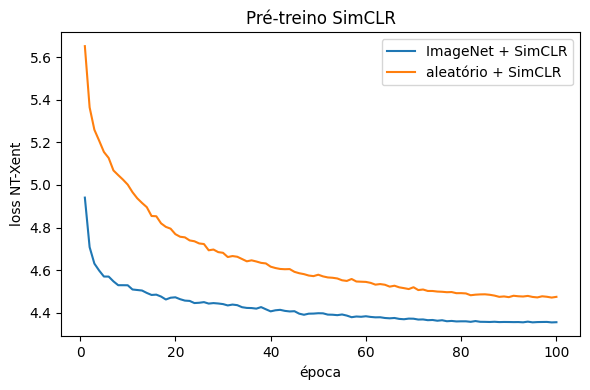

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, f in [("ImageNet + SimCLR", "imagenet_ssl_log.csv"), ("aleatório + SimCLR", "random_ssl_log.csv")]:
    d = pd.read_csv(OUT1 / f); ax.plot(d.epoch, d.loss, label=name)
ax.set(xlabel="época", ylabel="loss NT-Xent", title="Pré-treino SimCLR"); ax.legend(); fig.tight_layout()
fig.savefig(OUT1 / "ssl_loss.png", dpi=120); plt.show()

## 1.1 Avaliação Linear (Linear Probe) — 3 backbones lado a lado

Congelamos o backbone (nenhum peso convolucional é atualizado) e treinamos **apenas um classificador linear** (`512 -> 21`) sobre as características extraídas das 105 imagens rotuladas (`rotulos_5.csv`), escolhendo a melhor época pelo F1 macro no `val` e avaliando uma única vez no `test_public`.

Comparamos lado a lado:
1. **ImageNet puro** (sem pré-treino no domínio);
2. **ImageNet + SimCLR** (pré-treino auto-supervisionado nas 6.505 imagens do `train`);
3. **Aleatório + SimCLR** (pré-treino auto-supervisionado do zero nas 6.505 imagens).

In [14]:
import torch.nn as nn

def build_resnet_from_backbone(backbone_ckpt_path=None, pretrained_imagenet=False, freeze_backbone=False):
    """Monta uma ResNet-18 para classificação (21 classes) a partir de pesos do backbone SimCLR ou ImageNet."""
    m = C.resnet18(NC, pretrained=pretrained_imagenet)
    if backbone_ckpt_path is not None:
        state = torch.load(backbone_ckpt_path, map_location="cpu")
        missing, unexpected = m.load_state_dict(state, strict=False)
        assert set(missing) == {"fc.weight", "fc.bias"} and not unexpected, f"Chaves inesperadas: {missing} / {unexpected}"
    if freeze_backbone:
        for name_p, param in m.named_parameters():
            if not name_p.startswith("fc."):
                param.requires_grad = False
    return m

def fit_linear_probe(model, train_dl, val_dl, epochs=40, lr=1e-2):
    """Treina apenas a camada linear (fc) com o backbone congelado em modo eval (BatchNorm fixo)."""
    device = C.DEVICE
    model.to(device)
    opt = torch.optim.AdamW(model.fc.parameters(), lr=lr, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    ce = nn.CrossEntropyLoss()
    history, best = [], {"f1": -1}
    for ep in range(1, epochs + 1):
        model.eval()
        tl, tc, n = 0.0, 0, 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = ce(out, y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tl += loss.item() * len(y)
            tc += (out.argmax(1) == y).sum().item()
            n += len(y)
        sched.step()
        v = C.evaluate(model, val_dl, device, NC)
        history.append({"epoch": ep, "train_loss": tl / n, "train_acc": tc / n,
                        "val_loss": v["loss"], "val_acc": v["acc"], "val_f1": v["f1_macro"]})
        if v["f1_macro"] > best["f1"]:
            best = {"f1": v["f1_macro"], "epoch": ep, "state": {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}}
    return history, best["epoch"], best["state"]

lp_csv = OUT1 / "linear_probe_3backbones.csv"
if not FORCE_RETRAIN and lp_csv.exists():
    df_lp = pd.read_csv(lp_csv)
    print("Resultados carregados de", lp_csv.name)
else:
    backbones_lp = [
        ("ImageNet puro", None, True),
        ("ImageNet + SimCLR (min_scale=0.08)", OUT1 / "imagenet_ssl_backbone.pt", False),
        ("Aleatório + SimCLR (min_scale=0.08)", OUT1 / "random_ssl_backbone.pt", False),
    ]
    rows_lp = []
    for label_bb, ckpt_p, pre_im in backbones_lp:
        C.set_seed(SEED)
        m_lp = build_resnet_from_backbone(ckpt_p, pretrained_imagenet=pre_im, freeze_backbone=True)
        hist_lp, ep_lp, st_lp = fit_linear_probe(m_lp, make_loader(SEED), val_dl, epochs=40, lr=1e-2)
        m_lp.load_state_dict(st_lp)
        v_metrics = C.evaluate(m_lp, val_dl, C.DEVICE, NC)
        t_metrics = C.evaluate(m_lp, test_dl, C.DEVICE, NC)
        rows_lp.append({
            "Backbone (Linear Probe)": label_bb,
            "Melhor época (val)": ep_lp,
            "F1 macro (val)": round(v_metrics["f1_macro"], 4),
            "F1 macro (test_public)": round(t_metrics["f1_macro"], 4),
            "Acurácia (test_public)": round(t_metrics["acc"], 4),
        })
    df_lp = pd.DataFrame(rows_lp)
    df_lp.to_csv(lp_csv, index=False)
df_lp


,Backbone (Linear Probe),Melhor época (val),F1 macro (val),F1 macro (test_public),Acurácia (test_public)
0,ImageNet puro,13,0.4036,0.4705,0.5142
1,ImageNet + SimCLR (min_scale=0.08),14,0.3909,0.4266,0.4439
2,Aleatório + SimCLR (min_scale=0.08),20,0.3108,0.3362,0.3896


## 1.2 Experimento obrigatório sobre aumentação (`RandomResizedCrop`)

**O problema no domínio de câmeras trap:**
No SimCLR padrão (`min_scale=0.08`), um recorte aleatório pode pegar apenas 8% da área da imagem. Como em 1/4 das fotos de câmera trap o animal ocupa menos de 2% do quadro e a mesma câmera fotografa sempre o **mesmo fundo**, dois recortes pequenos quase nunca contêm o animal — ambos mostram apenas troncos, folhas ou chão daquela câmera.

**O que a rede aprende a aproximar nesse caso?**
Ao forçar a perda NT-Xent a aproximar dois recortes de fundo da mesma foto, o backbone aprende um **atalho de câmera/cenário** (textura da vegetação, iluminação/infravermelho e geometria do local fixo), agrupando imagens pela câmera/horário em vez das características morfológicas da espécie.

**Mudança testada:**
Aumentamos o limite inferior do recorte de `min_scale=0.08` para **`min_scale=0.40`** (cada view preserva entre 40% e 100% da imagem), aumentando drasticamente a probabilidade de o animal estar presente nas duas views positivas. Pré-treinamos o backbone ImageNet + SimCLR com `min_scale=0.40` e comparamos tanto na avaliação linear quanto no fine-tuning.

In [ ]:
# Pré-treino SimCLR com recorte menos agressivo (min_scale=0.40 em vez de 0.08)
_, log_img_s40 = S.pretrain("imagenet", EPOCHS_SSL, OUT1, "imagenet_ssl_s40", bs=BS_SSL, img_size=SIZE_SSL, min_scale=0.40, force=FORCE_RETRAIN)


[imagenet_ssl_s40] ep 1/100 loss 4.7045 (40s)
[imagenet_ssl_s40] ep 2/100 loss 4.4734 (39s)
[imagenet_ssl_s40] ep 3/100 loss 4.4253 (40s)
[imagenet_ssl_s40] ep 4/100 loss 4.3970 (39s)
[imagenet_ssl_s40] ep 5/100 loss 4.3825 (39s)
[imagenet_ssl_s40] ep 6/100 loss 4.3708 (38s)
[imagenet_ssl_s40] ep 7/100 loss 4.3648 (39s)
[imagenet_ssl_s40] ep 8/100 loss 4.3588 (38s)
[imagenet_ssl_s40] ep 9/100 loss 4.3542 (39s)
[imagenet_ssl_s40] ep 10/100 loss 4.3484 (40s)
[imagenet_ssl_s40] ep 11/100 loss 4.3459 (39s)
[imagenet_ssl_s40] ep 12/100 loss 4.3441 (40s)
[imagenet_ssl_s40] ep 13/100 loss 4.3407 (40s)
[imagenet_ssl_s40] ep 14/100 loss 4.3442 (40s)
[imagenet_ssl_s40] ep 15/100 loss 4.3419 (39s)
[imagenet_ssl_s40] ep 16/100 loss 4.3369 (39s)
[imagenet_ssl_s40] ep 17/100 loss 4.3469 (39s)
[imagenet_ssl_s40] ep 18/100 loss 4.3405 (39s)
[imagenet_ssl_s40] ep 19/100 loss 4.3343 (40s)
[imagenet_ssl_s40] ep 20/100 loss 4.3368 (39s)
[imagenet_ssl_s40] ep 21/100 loss 4.3435 (40s)
[imagenet_ssl_s40] ep 

In [ ]:
# Avaliação linear do backbone com min_scale=0.40 comparada aos anteriores
aug_lp_csv = OUT1 / "linear_probe_comparacao_completa.csv"
if not FORCE_RETRAIN and aug_lp_csv.exists():
    df_aug_lp = pd.read_csv(aug_lp_csv)
    print("Resultados carregados de", aug_lp_csv.name)
else:
    C.set_seed(SEED)
    m_lp40 = build_resnet_from_backbone(OUT1 / "imagenet_ssl_s40_backbone.pt", pretrained_imagenet=False, freeze_backbone=True)
    _, ep_lp40, st_lp40 = fit_linear_probe(m_lp40, make_loader(SEED), val_dl, epochs=40, lr=1e-2)
    m_lp40.load_state_dict(st_lp40)
    v40 = C.evaluate(m_lp40, val_dl, C.DEVICE, NC)
    t40 = C.evaluate(m_lp40, test_dl, C.DEVICE, NC)

    df_aug_lp = pd.concat([
        df_lp,
        pd.DataFrame([{
            "Backbone (Linear Probe)": "ImageNet + SimCLR (min_scale=0.40)",
            "Melhor época (val)": ep_lp40,
            "F1 macro (val)": round(v40["f1_macro"], 4),
            "F1 macro (test_public)": round(t40["f1_macro"], 4),
            "Acurácia (test_public)": round(t40["acc"], 4),
        }])
    ], ignore_index=True)
    df_aug_lp.to_csv(aug_lp_csv, index=False)
df_aug_lp


## 1.3 Fine-tuning completo com os 105 rótulos (`rotulos_5.csv`)

Agora descongelamos todo o modelo e fazemos fine-tuning nos 105 rótulos usando exatamente o mesmo protocolo do piso (b) (`224 px`, `lr=3e-4`, `20 épocas`, melhor época escolhida pelo F1 macro no `val`).
Comparamos os backbones pré-treinados com `min_scale=0.08` e `min_scale=0.40`, e selecionamos para representar o método da Trilha A aquele que obtiver maior F1 macro no **`val`** (sem olhar o `test_public` para escolher).

In [ ]:
ft_csv = OUT1 / "finetuning_comparacao.csv"
best_pt = OUT1 / f"trilha_a_best_b{BUDGET}_s{SEED}.pt"

if not FORCE_RETRAIN and ft_csv.exists() and best_pt.exists():
    df_ft = pd.read_csv(ft_csv)
    print("Resultados carregados de", ft_csv.name)
else:
    rows_ft = []
    ft_states = {}
    for tag_ft, ckpt_name in [("simclr_s08", "imagenet_ssl_backbone.pt"), ("simclr_s40", "imagenet_ssl_s40_backbone.pt")]:
        C.set_seed(SEED)
        m_ft = build_resnet_from_backbone(OUT1 / ckpt_name, pretrained_imagenet=False, freeze_backbone=False)
        hist_ft, ep_ft, st_ft = C.fit(m_ft, make_loader(SEED), val_dl, EPOCHS_RESNET, lr=3e-4, num_classes=NC, verbose=False)
        m_ft.load_state_dict(st_ft)
        v_ft = C.evaluate(m_ft, val_dl, C.DEVICE, NC)
        t_ft = C.evaluate(m_ft, test_dl, C.DEVICE, NC)
        torch.save(st_ft, OUT1 / f"{tag_ft}_ft_b{BUDGET}_s{SEED}.pt")
        pd.DataFrame(hist_ft).to_csv(OUT1 / f"{tag_ft}_ft_b{BUDGET}_s{SEED}_history.csv", index=False)
        ft_states[tag_ft] = (st_ft, v_ft, t_ft, ep_ft)
        rows_ft.append({
            "Modelo (Fine-tuning 105 rótulos)": tag_ft,
            "Melhor época (val)": ep_ft,
            "F1 macro (val)": round(v_ft["f1_macro"], 4),
            "F1 macro (test_public)": round(t_ft["f1_macro"], 4),
            "Acurácia (test_public)": round(t_ft["acc"], 4),
        })

    df_ft = pd.DataFrame(rows_ft)
    df_ft.to_csv(ft_csv, index=False)

    best_tag = max(ft_states.keys(), key=lambda k: ft_states[k][1]["f1_macro"])
    best_st, best_v, best_t, best_ep = ft_states[best_tag]
    torch.save(best_st, best_pt)
    print(f"Variante escolhida no val: {best_tag} (val F1={best_v['f1_macro']:.4f}) -> test_public F1={best_t['f1_macro']:.4f}, acc={best_t['acc']:.4f}")

    cb = ROOT / "curva_orcamento.csv"
    rows_cb = pd.read_csv(cb)
    rows_cb = rows_cb[~((rows_cb.metodo == "trilha_a_simclr") & (rows_cb.orcamento == BUDGET) & (rows_cb.seed == SEED))]
    rows_cb = pd.concat([rows_cb, pd.DataFrame([["trilha_a_simclr", BUDGET, SEED, round(best_t["f1_macro"], 4), round(best_t["acc"], 4)]], columns=rows_cb.columns)], ignore_index=True)
    rows_cb.to_csv(cb, index=False)
df_ft
